# Measuring the radius of curvature of lenses with a Fizeau interferometer

The radius of curvature $R$ of a spherical lens surface is measured
interferometrically by testing the surface with a converging spherical wave
from a **transmission sphere** (TS) and moving it along the axis between the
two positions in which the interferogram is a null:

- **confocal**: the centre of curvature of the surface lies in the focus of
  the TS; every ray hits the surface at normal incidence and returns on
  itself,
- **cat's eye**: the vertex of the surface lies in the focus; the beam is
  reflected by a tiny area around the vertex and returns on the opposite
  side of the pupil.

The distance between the two positions, read from a length measuring stage,
is the radius, $R = z_\mathrm{cat} - z_\mathrm{confocal}$ (with the sign
convention of `pyoptics.raytrace`: $R > 0$ for a centre of curvature
downstream, i.e. a convex surface facing the TS). Near either position, a
displacement of the surface turns the null into defocus and tilt fringes,
and fitting them gives the null positions with nanometre resolution, so the
operator does not have to null by eye.

This notebook builds the setup from the ray tracer and the interferometry
module:

1. a stigmatic transmission sphere (an ellipsoid in fused silica with a
   reference surface concentric with its focus), traced unfolded in double
   pass (`raytrace.double_pass()`), with the optical path of test and
   reference beams on the camera (`System.ray_map()`),
2. the interferograms of a misaligned test sphere near confocal and cat's
   eye,
3. the first order model of a displaced sphere and the pupil mapping of the
   TS (`interferometry.fit_sphere_displacement()`),
4. a measurement with phase shifting (Hariharan), unwrapping and fitting,
   its repeatability with camera noise and the bias of the textbook
   formula from the defocus Zernike,
5. single frame analysis with tilt fringes (Takeda),
6. form errors of the test surface: the measured surface map and why the
   radius depends on the evaluated aperture,
7. convex and concave test surfaces, the working range of the TS and an
   error budget.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from pyoptics.bases import FringeZernikes
from pyoptics.interferometry import (aplanatic_directions, fit_sphere_displacement,
                                     fourier_fringe_analysis, interferogram, phase_shifts,
                                     psi_hariharan, sphere_displacement_phase)
from pyoptics.processing import CameraNoiser
from pyoptics.raytrace import Surface, System, double_pass, fused_silica
from pyoptics.unwrap import unwrap

plt.rcParams.update({"figure.dpi": 100, "font.size": 11})

## 1. Transmission sphere and the unfolded double pass

The TS turns the collimated beam of the interferometer into a spherical
wave. Its last surface is the **reference surface**: it is concentric with
the focus, so the rays meet it at normal incidence and the light it
reflects (about 3.5 % from bare fused silica) returns as a plane wave, the
reference beam. The transmitted light is the test wave.

A real TS is a multi-element aplanat. Here, a single element does the job
exactly: collimated light refracted into glass by an ellipsoid with the
conic constant $K = -1/n^2$ converges without aberration to its far focal
point, at $nR_1/(n - 1)$ behind the vertex; the second surface, concentric
with that point, lets the converging wave leave the glass unchanged. With
$R_1 = 25$ mm and fused silica at the HeNe wavelength of 632.8 nm, this is
an f/3.1 TS (NA 0.16) for a 25 mm beam.

The ray tracer is sequential, so both arms are traced unfolded:
`double_pass()` appends the surfaces in reverse order behind the mirror
(the reference surface for the reference arm, the test surface for the test
arm). The returning beams end on a detector plane 10 mm in front of the TS.
An interferometer images the test surface onto the camera with further
optics; for this geometry (null tests, nearly collimated return beams) the
detector plane in the collimated space shows the same phase.

`System.ray_map()` traces a grid of rays and interpolates their optical
path onto the camera pixels. Geometrical optics gives the field there as
$\exp(ik_0\,\mathrm{OPL})$, so the phase of the interferogram is
$\varphi = k_0(\mathrm{OPL}_\mathrm{test} - \mathrm{OPL}_\mathrm{ref})$, in
the convention of `interferometry` (a test wave that runs ahead has
$\varphi > 0$).

In [2]:
WL = 632.8e-6  # mm
n_ts = fused_silica(632.8)
R1, T1, A = 25.0, 8.0, 12.5  # first radius, centre thickness, beam radius
K1 = -1/n_ts**2
F = n_ts*R1/(n_ts - 1)  # focus, from the first vertex
R2 = F - T1  # reference surface, concentric with the focus
DETECTOR = -10.0  # detector plane, z


def ts_surfaces(cavity=None):
    # cavity: distance from the reference surface to the test surface
    s1 = Surface(R1, T1, material=fused_silica, conic=K1, semi_diameter=A, label="TS 1")
    if cavity is None:  # reference arm: reflection at the reference surface
        return [s1, Surface(R2, mirror=True, semi_diameter=A, label="reference")]
    return [s1, Surface(R2, cavity, n_after=1.0, semi_diameter=A, label="reference")]


def reference_arm():
    return System(double_pass(ts_surfaces(), image_distance=DETECTOR), 0, WL)


def test_arm(R, z, decenter=(0.0, 0.0), aspheric=(), semi_diameter=20.0):
    # test surface with radius R and the vertex at z (from the first TS vertex)
    test = Surface(R, mirror=True, decenter=decenter, aspheric=aspheric,
                   semi_diameter=semi_diameter, label="test")
    return System(double_pass(ts_surfaces(z - T1) + [test], image_distance=DETECTOR), 0, WL)


x = np.linspace(-13, 13, 256)  # camera, mm in the detector plane
X, Y = np.meshgrid(x, x)
ref = reference_arm().ray_map(x, x, field=0.0, N=128)
pupil = ref.mask & (np.hypot(X, Y) < A - 0.1)

R_TEST = 40.0  # convex test surface
z_conf, z_cat = F - R_TEST, F
probe = test_arm(R_TEST, z_conf).ray_map(x, x, field=0.0, N=128, surface=1)
marginal = test_arm(R_TEST, z_conf).trace_pupil(0.0, 0.0, 1.0)
NA = abs(marginal.directions[2, 0, 1])  # behind the reference surface
print("fused silica n = {:.5f}, focus {:.3f} mm behind the first vertex".format(n_ts, F))
print("reference surface R2 = {:.3f} mm, NA = {:.4f} (f/{:.2f})".format(R2, NA, 1/(2*np.tan(np.arcsin(NA)))))
print("reference beam flat to {:.1e} waves".format(np.ptp(ref.opl[pupil])/WL))

fused silica n = 1.45702, focus 79.702 mm behind the first vertex
reference surface R2 = 71.702 mm, NA = 0.1613 (f/3.06)
reference beam flat to 1.0e-10 waves


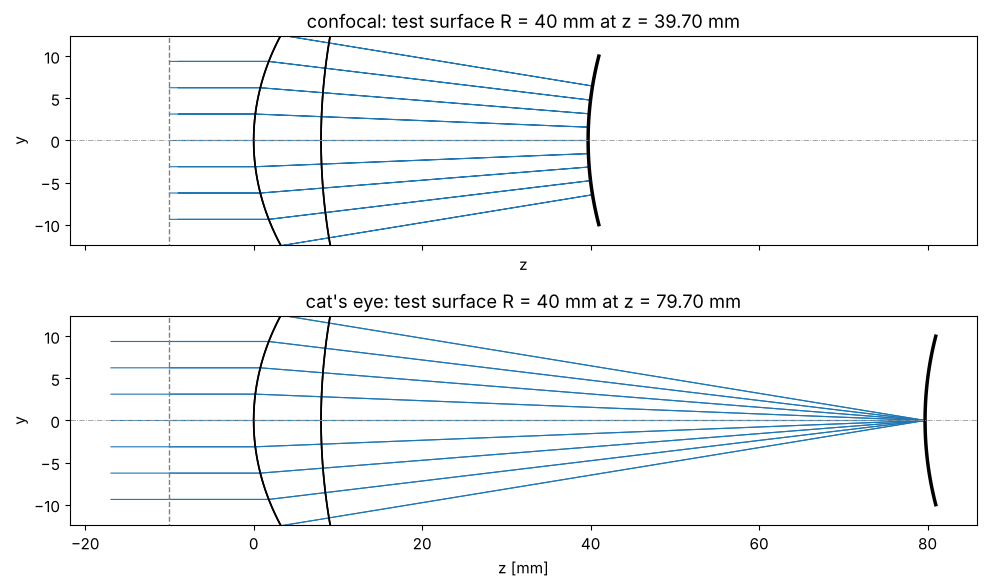

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for ax, z, title in zip(axes, (z_conf, z_cat), ("confocal", "cat's eye")):
    test_arm(R_TEST, z, semi_diameter=10.0).draw(ax=ax, fields=[0.0], n_rays=9)
    ax.set_title("{}: test surface R = {:.0f} mm at z = {:.2f} mm".format(title, R_TEST, z))
axes[1].set_xlabel("z [mm]")
plt.tight_layout()

Both arms return through the TS, so a well made TS hardly matters for the
null itself, and the stigmatic design here returns both arms as plane waves
to numerical precision. With a spherical first surface instead of the
ellipsoid, this singlet would have more than 100 waves of spherical
aberration and the test wave would no longer be spherical; real TSs are
corrected to about $\lambda/20$ and calibrated against a reference sphere.

The interferogram visibility follows from the Fresnel reflectances: the
reference surface reflects $\rho_\mathrm{ref} = ((n-1)/(n+1))^2$, the test
beam passes it twice and is reflected by the bare test surface (N-BK7,
$n \approx 1.515$). Multiple reflections in the cavity are neglected at
these low reflectances.

In [4]:
def fresnel(n):
    return ((n - 1)/(n + 1))**2


I_ref = fresnel(n_ts)
I_test = (1 - fresnel(n_ts))**2*fresnel(1.515)
VISIBILITY = 2*np.sqrt(I_ref*I_test)/(I_ref + I_test)
I0 = I_ref + I_test
print("reference {:.2%}, test {:.2%} of the incident power, visibility {:.4f}".format(
    I_ref, I_test, VISIBILITY))


def phase_map(system, surface=1):
    # phase of the test beam relative to the reference on the camera
    m = system.ray_map(x, x, field=0.0, N=128, surface=surface)
    return 2*np.pi*(m.opl - ref.opl)/WL, m


for z, name in ((z_conf, "confocal"), (z_cat, "cat's eye")):
    phi, m = phase_map(test_arm(R_TEST, z))
    ok = pupil & m.mask
    print("{:10s}: phase peak-to-valley {:.1e} waves over {:.0f} % of the pupil".format(
        name, np.ptp(phi[ok])/(2*np.pi), 100*ok.sum()/pupil.sum()))

reference 3.46%, test 3.91% of the incident power, visibility 0.9981


confocal  : phase peak-to-valley 2.2e-10 waves over 100 % of the pupil


cat's eye : phase peak-to-valley 5.2e-10 waves over 100 % of the pupil


## 2. Interferograms of a misaligned test sphere

Moving the test sphere away from a null position adds fringes. Near
confocal, an axial displacement gives power (circular) fringes and a
lateral displacement tilt fringes. Near cat's eye, an axial displacement
gives power fringes as well, while a lateral displacement leaves the null
intact: the beam is reflected at the vertex region like by a plane mirror
(lateral motion keeps the path lengths), and the small tilt of the surface
normal there only shifts the returning beam laterally. This insensitivity is
what makes the cat's eye a robust axial reference. The interferograms below
are computed from the traced optical paths, i.e. exactly (within
geometrical optics), not from the first order model.

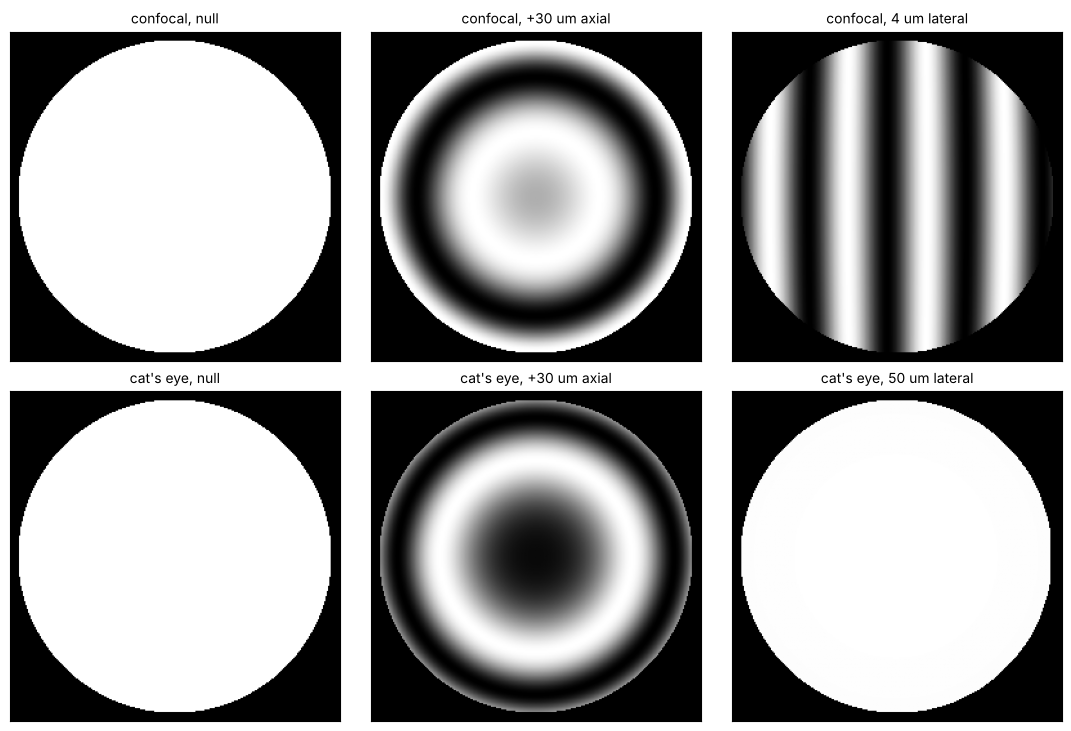

In [5]:
cases = [("confocal, null", z_conf, (0, 0)), ("confocal, +30 um axial", z_conf + 0.03, (0, 0)),
         ("confocal, 4 um lateral", z_conf, (0.004, 0)), ("cat's eye, null", z_cat, (0, 0)),
         ("cat's eye, +30 um axial", z_cat + 0.03, (0, 0)), ("cat's eye, 50 um lateral", z_cat, (0.05, 0))]
fig, axes = plt.subplots(2, 3, figsize=(11, 7.4))
for ax, (title, z, dec) in zip(axes.flat, cases):
    phi, m = phase_map(test_arm(R_TEST, z, decenter=dec))
    ok = pupil & m.mask
    I = np.where(ok, interferogram(np.nan_to_num(phi), visibility=VISIBILITY, I0=I0), 0.0)
    ax.imshow(I, extent=[x[0], x[-1], x[0], x[-1]], origin="lower", cmap="gray")
    ax.set_title(title, fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()

## 3. The displaced sphere to first order and the pupil mapping of the TS

A displacement $\mathbf d$ of the sphere from a null position lengthens the
path of the ray with the direction $\hat{\mathbf n}$ by
$\mathbf d\cdot\hat{\mathbf n}$ per pass, so the phase is

$$\varphi = 2k\,(d_x n_x + d_y n_y + d_z n_z) + \text{const.}$$

(`interferometry.sphere_displacement_phase()`). On axis, $n_z = \cos\theta$
and the axial term $2kd_z\cos\theta \approx 2kd_z(1 - \theta^2/2)$ is
defocus. `fit_sphere_displacement()` fits this model by least squares. In
cat's eye, the lateral terms are replaced by a free tilt
(`lateral=False`).

The model needs the direction of the test ray at every camera pixel, i.e.
the **pupil mapping** of the TS. An aplanatic TS obeys the sine condition,
$\sin\theta = \mathrm{NA}\,\rho$ (`aplanatic_directions()`). The
ellipsoid singlet is stigmatic but not aplanatic: in the zones, its rays
leave at a smaller angle than the sine condition gives. `ray_map(..., surface=1)`
returns the directions of the traced test rays behind the reference
surface, so the exact mapping is available.

traced directions : d = (2.0000, -1.0000, 3.0002) um, residual 3.2e-06 waves rms
aplanatic mapping : d = (1.9802, -0.9901, 2.9958) um, residual 3.7e-03 waves rms
true displacement : d = (2.0000, -1.0000, 3.0000) um


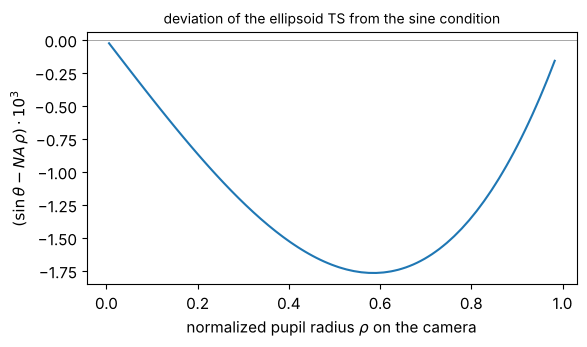

In [6]:
n_traced = probe.directions
n_aplanatic = aplanatic_directions(x, x, A, NA)
rho = np.hypot(X, Y)/A
i0 = len(x)//2  # one row through the centre
sel = pupil[i0] & (x > 0)

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(rho[i0, sel], 1e3*(np.hypot(*n_traced[i0, sel][:, :2].T) - NA*rho[i0, sel]))
ax.axhline(0, color="0.6", lw=0.6)
ax.set_xlabel(r"normalized pupil radius $\rho$ on the camera")
ax.set_ylabel(r"$(\sin\theta - NA\,\rho)\cdot 10^3$")
ax.set_title("deviation of the ellipsoid TS from the sine condition", fontsize=10)
plt.tight_layout()

d_true = np.array([0.002, -0.001, 0.003])  # mm
phi, m = phase_map(test_arm(R_TEST, z_conf + d_true[2], decenter=d_true[:2]))
ok = pupil & m.mask
for name, n_dir in (("traced directions", n_traced), ("aplanatic mapping", n_aplanatic)):
    d_fit, res = fit_sphere_displacement(phi, n_dir, WL, mask=ok)
    print("{:18s}: d = ({:.4f}, {:.4f}, {:.4f}) um, residual {:.1e} waves rms".format(
        name, *(1e3*d_fit), np.std(res[ok])/(2*np.pi)))
print("true displacement : d = ({:.4f}, {:.4f}, {:.4f}) um".format(*(1e3*d_true)))

With the traced directions, the first order model recovers a displacement
of a few micrometres to better than a nanometre; with the aplanatic
assumption on this non-aplanatic TS, the lateral components are off by 1 %
and the fit leaves a residual of a few milliwaves. In practice the mapping
comes from the TS design data or from a calibration, e.g. a known stage
displacement.

## 4. A measurement: phase shifting near both null positions

The operator nulls the fringes roughly near both positions and reads the
stage. The interferometer records five phase shifted frames (Hariharan's
algorithm, $\pi/2$ steps, insensitive to linear phase shifter errors) with
camera noise at each position. The phase is unwrapped (quality guided) and
the displacement fit gives the offsets from the null positions:

$$R = (z_2 - d_{z,2}) - (z_1 - d_{z,1}),$$

with the stage readings $z_1$ (near confocal) and $z_2$ (near cat's eye).

confocal offset  d = (+0.800, -0.500, +1.701) um
cat's eye offset dz = -2.401 um
R = 40.000002 mm (true 40.000000 mm), error +2.0 nm


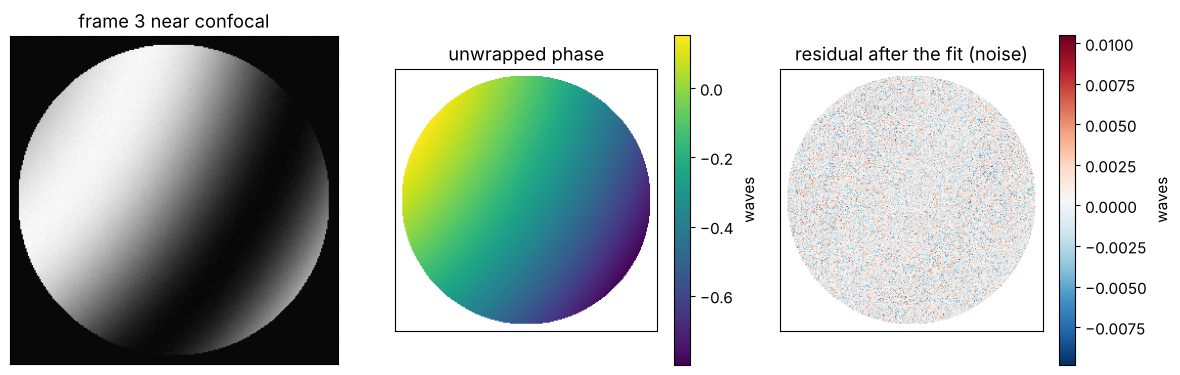

In [7]:
rng = np.random.default_rng(1)
shifts = phase_shifts(5, step=np.pi/2, start=-np.pi)
noiser = CameraNoiser("gaussian", sigma=0.01, relative=True, rng=rng)
STAGE_NOISE = 0.1e-3  # mm, stage reading (encoder) repeatability

# roughly nulled positions: a few micrometres off, slightly decentred
pos_conf = dict(z=z_conf + 1.7e-3, decenter=(0.8e-3, -0.5e-3))
pos_cat = dict(z=z_cat - 2.4e-3, decenter=(3e-3, 1e-3))
phi_conf, m_conf = phase_map(test_arm(R_TEST, pos_conf["z"], pos_conf["decenter"]))
phi_cat, m_cat = phase_map(test_arm(R_TEST, pos_cat["z"], pos_cat["decenter"]))
ok_conf, ok_cat = pupil & m_conf.mask, pupil & m_cat.mask


def measure_phase(phi, ok, noiser):
    frames = interferogram(np.nan_to_num(phi), visibility=VISIBILITY, I0=I0, shift=shifts,
                           noiser=noiser)
    wrapped, modulation = psi_hariharan(frames)
    return unwrap(np.where(ok, wrapped, 0.0), mask=ok), frames


def measure_radius(noiser=None, stage_noise=0.0, rng=None):
    unwrapped_conf, frames = measure_phase(phi_conf, ok_conf, noiser)
    unwrapped_cat, _ = measure_phase(phi_cat, ok_cat, noiser)
    d1, res1 = fit_sphere_displacement(unwrapped_conf, n_traced, WL, mask=ok_conf)
    d2, res2 = fit_sphere_displacement(unwrapped_cat, n_traced, WL, mask=ok_cat, lateral=False)
    z1, z2 = pos_conf["z"], pos_cat["z"]
    if stage_noise:
        z1, z2 = z1 + stage_noise*rng.normal(), z2 + stage_noise*rng.normal()
    return (z2 - d2[2]) - (z1 - d1[2]), d1, d2, frames, unwrapped_conf, res1


R_meas, d1, d2, frames, unwrapped_conf, res1 = measure_radius(noiser)
print("confocal offset  d = ({:+.3f}, {:+.3f}, {:+.3f}) um".format(*(1e3*d1)))
print("cat's eye offset dz = {:+.3f} um".format(1e3*d2[2]))
print("R = {:.6f} mm (true {:.6f} mm), error {:+.1f} nm".format(R_meas, R_TEST, 1e6*(R_meas - R_TEST)))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
ext = [x[0], x[-1], x[0], x[-1]]
axes[0].imshow(frames[..., 2]*ok_conf, extent=ext, origin="lower", cmap="gray")
axes[0].set_title("frame 3 near confocal")
im = axes[1].imshow(np.where(ok_conf, unwrapped_conf/(2*np.pi), np.nan), extent=ext, origin="lower")
plt.colorbar(im, ax=axes[1], label="waves")
axes[1].set_title("unwrapped phase")
im = axes[2].imshow(np.where(ok_conf, res1/(2*np.pi), np.nan), extent=ext, origin="lower", cmap="RdBu_r")
plt.colorbar(im, ax=axes[2], label="waves")
axes[2].set_title("residual after the fit (noise)")
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()

The fit removes the misalignment completely, the residual is camera noise.
Repeating the measurement shows how much the fringe analysis and the stage
contribute to the scatter of $R$:

In [8]:
R_fringes = [measure_radius(noiser)[0] for _ in range(20)]
R_total = [measure_radius(noiser, STAGE_NOISE, rng)[0] for _ in range(20)]
print("fringe analysis only: R scatter {:.2f} nm rms".format(1e6*np.std(R_fringes)))
print("with the stage noise: R scatter {:.0f} nm rms (stage readings {:.0f} nm each)".format(
    1e6*np.std(R_total), 1e6*STAGE_NOISE))

fringe analysis only: R scatter 0.95 nm rms
with the stage noise: R scatter 175 nm rms (stage readings 100 nm each)


The fringe analysis resolves the null positions to fractions of a
nanometre; the uncertainty of $R$ comes from the stage (and, in a real
instrument, from the Abbe offset and the alignment of the stage axis, see
below).

**The textbook formula.** Interferometer software often derives the axial
offset from the defocus coefficient alone. To second order in $\theta$ and
for an aplanatic TS, the double pass phase in waves is
$W = -d_z\,\mathrm{NA}^2\rho^2/\lambda$, so the Fringe Zernike coefficient
$a_4$ of $Z_4 = 2\rho^2 - 1$ gives $d_z = -2\lambda a_4/\mathrm{NA}^2$. It
neglects the higher orders of $\cos\theta$ (which go into spherical
aberration $Z_9$) and the pupil mapping:

In [9]:
Z = FringeZernikes(x, x, R_norm=A)
basis = np.array([Z.eval_single(j)[ok_conf] for j in range(1, 10)]).T
a = np.linalg.lstsq(basis, unwrapped_conf[ok_conf]/(2*np.pi), rcond=None)[0]
dz_zernike = -2*WL*a[3]/NA**2
print("defocus Z4 = {:+.4f} waves, spherical Z9 = {:+.5f} waves".format(a[3], a[8]))
print("dz from Z4: {:+.4f} um, from the fit with the traced directions: {:+.4f} um".format(
    1e3*dz_zernike, 1e3*d1[2]))
print("relative error of the Z4 formula at NA {:.3f}: {:+.1%}".format(NA, dz_zernike/d1[2] - 1))

defocus Z4 = -0.0352 waves, spherical Z9 = -0.00072 waves
dz from Z4: +1.7112 um, from the fit with the traced directions: +1.7010 um
relative error of the Z4 formula at NA 0.161: +0.6%


At NA 0.16 the Z4 formula is off by about half a percent of the offset.
That is harmless if the operator nulls well (10 nm for 2 µm), but the
neglected terms grow with $\mathrm{NA}^2$, and with the offset; the full
model has no such bias.

## 5. A single frame with tilt fringes

Without a phase shifter (or with vibrations), a single interferogram with
a tilt carrier can be analysed with Takeda's Fourier transform method.
Decentring the test sphere near confocal by 12 µm gives about 12 tilt
fringes. `fourier_fringe_analysis()` with `remove_carrier=False` keeps the
tilt, which carries the lateral displacement, and the same fit as before
gives all three components.

Two things to watch: a single frame does not tell $\varphi$ from
$-\varphi$, and `find_carrier()` picks the sideband with $k_x > 0$, so the
direction of the carrier has to be known from the setup (here: a decentre
towards $-x$ tilts the fringes such that $k_x > 0$). And the model is first
order in $\mathbf d$: lateral decentres of $d_\perp$ bias $d_z$ by terms of
order $d_\perp^2/R$ (about 16 nm for 20 µm at $R$ = 40 mm), so the carrier
should stay moderate.

Takeda: d = (-12.002, -3.001, +1.7451) um, true (-12.000, -3.000, +1.7000) um
residual 0.004 waves rms


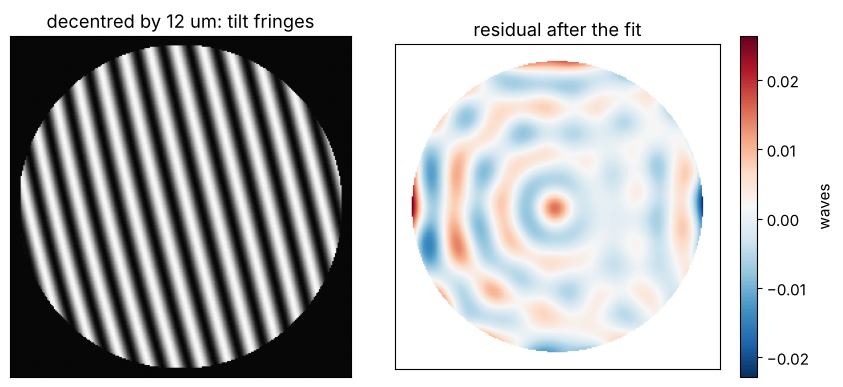

In [10]:
dec = (-0.012, -0.003)
phi_tilt, m = phase_map(test_arm(R_TEST, pos_conf["z"], decenter=dec))
ok = pupil & m.mask
I = interferogram(np.nan_to_num(phi_tilt), visibility=VISIBILITY, I0=I0,
                  noiser=CameraNoiser("gaussian", sigma=0.01, relative=True, rng=rng))
wrapped, modulation = fourier_fringe_analysis(I, x, x, mask=ok, remove_carrier=False)
inner = ok & (np.hypot(X, Y) < A - 0.8)  # the window rings near the pupil edge
unwrapped = unwrap(np.where(inner, wrapped, 0.0), mask=inner)
d_ftm, res = fit_sphere_displacement(unwrapped, n_traced, WL, mask=inner)
print("Takeda: d = ({:.3f}, {:.3f}, {:+.4f}) um, true ({:.3f}, {:.3f}, {:+.4f}) um".format(
    *(1e3*d_ftm), 1e3*dec[0], 1e3*dec[1], 1e3*(pos_conf["z"] - z_conf)))
print("residual {:.3f} waves rms".format(np.std(res[inner])/(2*np.pi)))

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(I*ok, extent=ext, origin="lower", cmap="gray")
axes[0].set_title("decentred by 12 um: tilt fringes")
im = axes[1].imshow(np.where(inner, res/(2*np.pi), np.nan), extent=ext, origin="lower", cmap="RdBu_r")
plt.colorbar(im, ax=axes[1], label="waves")
axes[1].set_title("residual after the fit")
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()

The single frame result is less accurate: the spectral window rings at
the pupil edge, and the ringing pattern correlates with defocus, which
biases $d_z$ by some 10 nm. That is plenty for alignment and for
measurements in a vibrating environment; phase shifting remains the method
for the best null positions.

## 6. Form errors of the test surface

A real surface deviates from the sphere. At confocal, the test wave meets
the surface at normal incidence, so a form error $h(x, y)$ (along the
normal) adds $2kh$ to the phase at the pixel whose ray hits the surface at
$(x, y)$; `ray_map(..., surface=2)` gives these points. Here the surface
gets a rotationally symmetric zone error, traced exactly as an $r^4$ term of
the surface (`aspheric=(A4,)`), and an astigmatism added to the phase at the
hit points (the ray tracer has no freeform surfaces). In cat's eye, the
beam only sees a sub-millimetre spot around the vertex, so form errors do
not show there.

The residual of the displacement fit at confocal is the surface map, i.e.
the measurement of the form error, in double pass.

surface 6.4 nm rms, 34.7 nm peak-to-valley
astigmatism Z5 = +14.39 nm (applied 15 nm amplitude), spherical Z9 = +6.16 nm


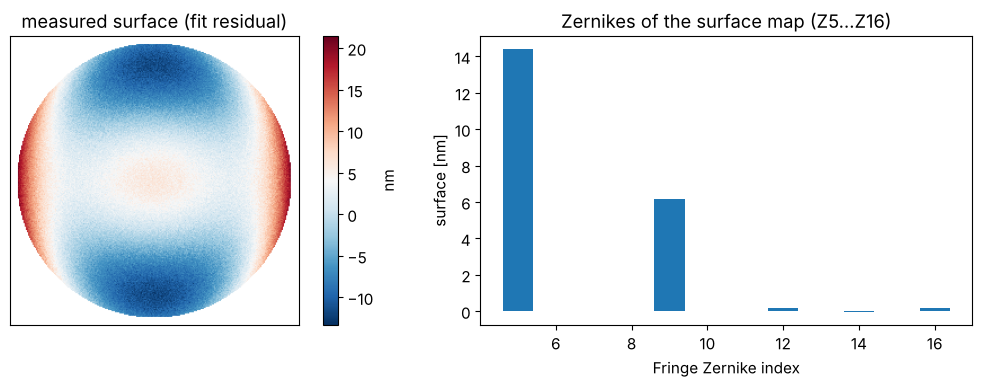

In [11]:
r_test = R_TEST*np.tan(np.arcsin(NA))  # radius of the tested area on the surface
A4 = 40e-6/r_test**4  # 40 nm zone error at the rim of the tested area
ASTIG = 15e-6  # 15 nm astigmatism amplitude at the rim


def form_error_phase(system):
    phi, m = phase_map(system, surface=2)
    xs, ys = m.points[..., 0], m.points[..., 1]
    h = ASTIG*(xs**2 - ys**2)/r_test**2
    return phi + 2*2*np.pi/WL*h, m


phi_form, m = form_error_phase(test_arm(R_TEST, pos_conf["z"], pos_conf["decenter"], aspheric=(A4,)))
ok = pupil & m.mask
unwrapped, _ = measure_phase(phi_form, ok, noiser)
d_form, res = fit_sphere_displacement(unwrapped, n_traced, WL, mask=ok)
surface_nm = 1e6*WL*res/(2*2*np.pi)  # double pass

Zs = np.array([Z.eval_single(j)[ok] for j in range(1, 17)]).T
c = np.linalg.lstsq(Zs, surface_nm[ok], rcond=None)[0]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
im = axes[0].imshow(np.where(ok, surface_nm, np.nan), extent=ext, origin="lower", cmap="RdBu_r")
plt.colorbar(im, ax=axes[0], label="nm")
axes[0].set_title("measured surface (fit residual)")
axes[0].set_xticks([])
axes[0].set_yticks([])
axes[1].bar(np.arange(5, 17), c[4:])
axes[1].set_xlabel("Fringe Zernike index")
axes[1].set_ylabel("surface [nm]")
axes[1].set_title("Zernikes of the surface map (Z5...Z16)")
plt.tight_layout()
print("surface {:.1f} nm rms, {:.1f} nm peak-to-valley".format(np.std(surface_nm[ok]), np.ptp(surface_nm[ok])))
print("astigmatism Z5 = {:+.2f} nm (applied {:.0f} nm amplitude), spherical Z9 = {:+.2f} nm".format(
    c[4], 1e6*ASTIG, c[8]))

**Which radius?** The zone error has a component that looks like defocus:
the best fitting sphere over the tested area is not the vertex sphere. The
fit assigns that component to the axial offset $d_z$, so the measured radius
is the radius of the best fit sphere, and it depends on the aperture over
which the fit is done. In the paraxial picture, fitting $r^4$ by a constant
and $r^2$ over a disk of radius $r_m$ gives the slope $r_m^2$, so the
curvature changes by $\Delta(1/2R) = A_4 r_m^2$, i.e.
$\Delta R \approx -2R^2A_4r_m^2$:

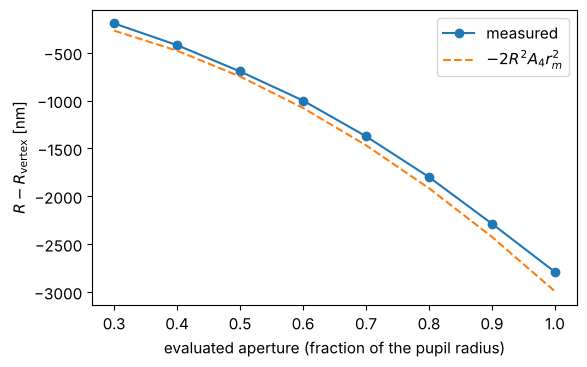

In [12]:
unwrapped_cat, _ = measure_phase(phi_cat, ok_cat, noiser)
d_cat = fit_sphere_displacement(unwrapped_cat, n_traced, WL, mask=ok_cat, lateral=False)[0]
fractions = np.linspace(0.3, 1.0, 8)
R_aperture, R_paraxial = [], []
for f in fractions:
    sub = ok & (np.hypot(X, Y) < f*A)
    d_sub = fit_sphere_displacement(unwrapped, n_traced, WL, mask=sub)[0]
    R_aperture.append((pos_cat["z"] - d_cat[2]) - (pos_conf["z"] - d_sub[2]))
    R_paraxial.append(R_TEST - 2*R_TEST**2*A4*(f*r_test)**2)

fig, ax = plt.subplots(figsize=(6, 3.8))
ax.plot(fractions, 1e6*(np.array(R_aperture) - R_TEST), "o-", label="measured")
ax.plot(fractions, 1e6*(np.array(R_paraxial) - R_TEST), "--", label=r"$-2R^2A_4r_m^2$")
ax.set_xlabel("evaluated aperture (fraction of the pupil radius)")
ax.set_ylabel(r"$R - R_\mathrm{vertex}$ [nm]")
ax.legend()
plt.tight_layout()

A radius specification therefore has to name the aperture (usually the
clear aperture of the lens) and whether the power part of the form error
counts as radius or as form. A zone error of 40 nm over the tested area
changes the radius by up to 3 µm, much more than the fringe analysis
resolves.

## 7. Convex and concave surfaces, and the working range

The same procedure measures concave surfaces, whose confocal position lies
behind the focus. The TS limits what can be measured:

- a convex surface must fit between the reference surface and the focus,
  $R < R_2$ (minus the lens thickness and a safety margin), and the beam
  footprint $R\tan\theta_\mathrm{max}$ on it sets the tested aperture; to
  test the full clear aperture of a strongly curved lens, choose a TS with
  a smaller f-number,
- a concave surface needs the stage travel $|R|$ beyond the focus and an
  aperture large enough for the footprint $|R|\tan\theta_\mathrm{max}$.

In [13]:
print("{:>9s} {:>10s} {:>12s} {:>14s} {:>12s}".format("R [mm]", "confocal", "cat's eye", "footprint [mm]", "error [nm]"))
for R in (15.0, 40.0, 65.0, -30.0, -150.0):
    zc = F - R
    p1 = dict(z=zc + 1.3e-3, decenter=(1e-3, 0.5e-3))
    p2 = dict(z=z_cat - 0.9e-3, decenter=(2e-3, 0.0))
    ph1, m1 = phase_map(test_arm(R, p1["z"], p1["decenter"], semi_diameter=1.2*abs(R)*np.tan(np.arcsin(NA))))
    ph2, m2 = phase_map(test_arm(R, p2["z"], p2["decenter"]))
    ok1, ok2 = pupil & m1.mask, pupil & m2.mask
    u1, _ = measure_phase(ph1, ok1, None)
    u2, _ = measure_phase(ph2, ok2, None)
    d1 = fit_sphere_displacement(u1, n_traced, WL, mask=ok1)[0]
    d2 = fit_sphere_displacement(u2, n_traced, WL, mask=ok2, lateral=False)[0]
    R_m = (p2["z"] - d2[2]) - (p1["z"] - d1[2])
    print("{:9.1f} {:10.3f} {:12.3f} {:14.2f} {:12.2f}".format(
        R, zc, z_cat, abs(R)*np.tan(np.arcsin(NA)), 1e6*(R_m - R)))

   R [mm]   confocal    cat's eye footprint [mm]   error [nm]


     15.0     64.702       79.702           2.45         0.05


     40.0     39.702       79.702           6.54         0.06


     65.0     14.702       79.702          10.63         0.08


    -30.0    109.702       79.702           4.90         0.09


   -150.0    229.702       79.702          24.52         0.08


Without noise, the procedure recovers convex and concave radii to the
residual of the first order model (sub-nanometre for micrometre offsets).

**Error budget.** With the fringe analysis at the nanometre level, the
radius error of an instrument comes from the length measurement and the
geometry:

| contribution | effect on $R$ | example ($R$ = 40 mm) |
|---|---|---|
| stage scale (encoder) error $\epsilon$ | $\epsilon R$ | 1 ppm: 40 nm |
| stage reading repeatability $\sigma_z$ | $\sqrt 2\,\sigma_z$ | 100 nm: 140 nm |
| stage axis tilted by $\alpha$ against the optical axis | the fit returns $d_x, d_y$ too; using only $d_z$: $R\alpha^2/2$ | 1 mrad: 20 nm |
| Abbe offset $a$ with a stage pitch change $\beta$ | $a\beta$ | 10 mm, 5 µrad: 50 nm |
| null offsets from the Z4 formula instead of the model | ~0.5 % of the offsets at NA 0.16 | 3 µm offsets: ~20 nm |
| form error (best fit sphere over the evaluated aperture) | $-2R^2A_4r_m^2$ | 40 nm zone: up to 3 µm |
| temperature of the test piece (fused silica $\alpha_T$ = 0.5 ppm/K, N-BK7 7 ppm/K) | $\alpha_T R\,\Delta T$ | N-BK7, 0.1 K: 28 nm |

The wavelength itself enters only through the small offsets $d_z$; the
radius is a length measurement by the stage.

## Summary

- `raytrace.double_pass()` unfolds interferometers (and other double pass
  setups) for the sequential ray tracer: the surfaces up to a mirror and
  back in reverse order, with the media of the forward pass.
- `System.ray_map()` interpolates the optical path (and the ray points and
  directions at any surface) onto a camera grid; the phase difference of
  the test and reference arms is the phase of the interferogram, which
  `interferometry.interferogram()` turns into fringes.
- A Fizeau interferometer with a stigmatic transmission sphere measures the
  radius of curvature as the distance between the confocal and the cat's
  eye null positions. The cat's eye is insensitive to lateral misalignment.
- `interferometry.fit_sphere_displacement()` fits the first order phase of
  a displaced sphere, $2k\,\mathbf d\cdot\hat{\mathbf n}$, to phase shifted
  (Hariharan) or single frame (Takeda) measurements and gives the null
  positions without nulling by eye; the pupil mapping of the TS
  (`aplanatic_directions()` or the traced directions) matters at the
  percent level, the Z4 shortcut has a bias that grows with the NA.
- The fringe analysis resolves the null positions to below a nanometre; the
  uncertainty of $R$ comes from the stage, alignment and temperature, and a
  surface with form errors has the radius of its best fit sphere over the
  evaluated aperture.